# Greedy против beam search (beam=4)

Сравниваем одну и ту же модель `baseline_001/checkpoint-147871` на **тех же 10 000 отложенных примеров**. Для обоих вариантов batch 64, FP16, лимит входа и генерации 256 токенов, сортировка входов по длине. Beam возвращает **один лучший кандидат**: измеряется pass@1.

Этот ноутбук читает готовые результаты; модель повторно не запускается. Новый эксперимент меняет только число beams, обучение и веса не меняются.

In [1]:
from pathlib import Path
import json
import math
from IPython.display import Code, Markdown, display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "inference.py").is_file())
GREEDY_DIR = PROJECT_ROOT / "artifacts/evaluations/checkpoint-147871_test10000_seed42_20261013_v3"
BEAM_DIR = PROJECT_ROOT / "artifacts/beam_search_20261013/beam4"
PLOT_DIR = PROJECT_ROOT / "artifacts/beam_search_20261013/plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

greedy = json.loads((GREEDY_DIR / "metrics.json").read_text())
beam = json.loads((BEAM_DIR / "metrics.json").read_text())
comparison = json.loads((BEAM_DIR / "comparison.json").read_text())
run = json.loads((BEAM_DIR / "run.json").read_text())
assert run["status"] == "complete"
assert comparison["identical_sample_and_references_verified"]
assert greedy["num_evaluated"] == beam["num_evaluated"]
print("Checkpoint:", run["checkpoint"])
print("SHA256 весов:", run["checkpoint_weights_sha256"])
print("Выбрано:", beam["num_examples"], "проверяемых эталонов:", beam["num_evaluated"])

Checkpoint: /home/artyom-step/workspace/nlp-hw2/artifacts/experiments/baseline_001/checkpoint-147871
SHA256 весов: ce2598e7682dec2bd6272a952df4990579008be4c88d4763353eea8854acf740
Выбрано: 10000 проверяемых эталонов: 9929


## Качество и стоимость генерации

pass@1 считается по строкам с исполнимым эталоном; bad code — по всем выбранным строкам. Тайминг включает токенизацию, генерацию и декодирование на одной A100. Greedy — сохранённый исходный замер с теми же настройками.

In [2]:
rows = [
    ("pass@1", f"{greedy['pass@1']:.2%}", f"{beam['pass@1']:.2%}"),
    ("Верных ответов", str(greedy['num_passed']), str(beam['num_passed'])),
    ("Исполнимых эталонов", str(greedy['num_evaluated']), str(beam['num_evaluated'])),
    ("Неисполнимый код", f"{greedy['bad_code_rate']:.2%}", f"{beam['bad_code_rate']:.2%}"),
    ("Достигнут лимит генерации", f"{greedy['hit_token_limit_rate']:.2%}", f"{beam['hit_token_limit_rate']:.2%}"),
    ("Средняя длина генерации, токены", f"{greedy['mean_generated_tokens']:.1f}", f"{beam['mean_generated_tokens']:.1f}"),
    ("Генерация 10 000 ответов, с", f"{greedy['total_seconds']:.1f}", f"{beam['total_seconds']:.1f}"),
]
display(Markdown("| Метрика | Greedy | Beam 4 |\n|---|---:|---:|\n" + "\n".join(f"| {label} | {a} | {b} |" for label, a, b in rows)))
lo, hi = comparison['paired_bootstrap_delta_95_ci_percentage_points']
display(Markdown(
    f"**Изменение pass@1: {comparison['delta_pass_at_1_percentage_points']:+.2f} п.п.** "
    f"Приближённый парный 95% bootstrap-интервал: [{lo:+.2f}; {hi:+.2f}] п.п. "
    f"**Отношение времени генерации: {comparison['inference_time_ratio']:.2f}×.**"
))

| Метрика | Greedy | Beam 4 |
|---|---:|---:|
| pass@1 | 64.98% | 67.44% |
| Верных ответов | 6452 | 6696 |
| Исполнимых эталонов | 9929 | 9929 |
| Неисполнимый код | 1.50% | 0.72% |
| Достигнут лимит генерации | 0.52% | 0.13% |
| Средняя длина генерации, токены | 66.4 | 68.5 |
| Генерация 10 000 ответов, с | 127.9 | 167.8 |

**Изменение pass@1: +2.46 п.п.** Приближённый парный 95% bootstrap-интервал: [+1.95; +2.96] п.п. **Отношение времени генерации: 1.31×.**

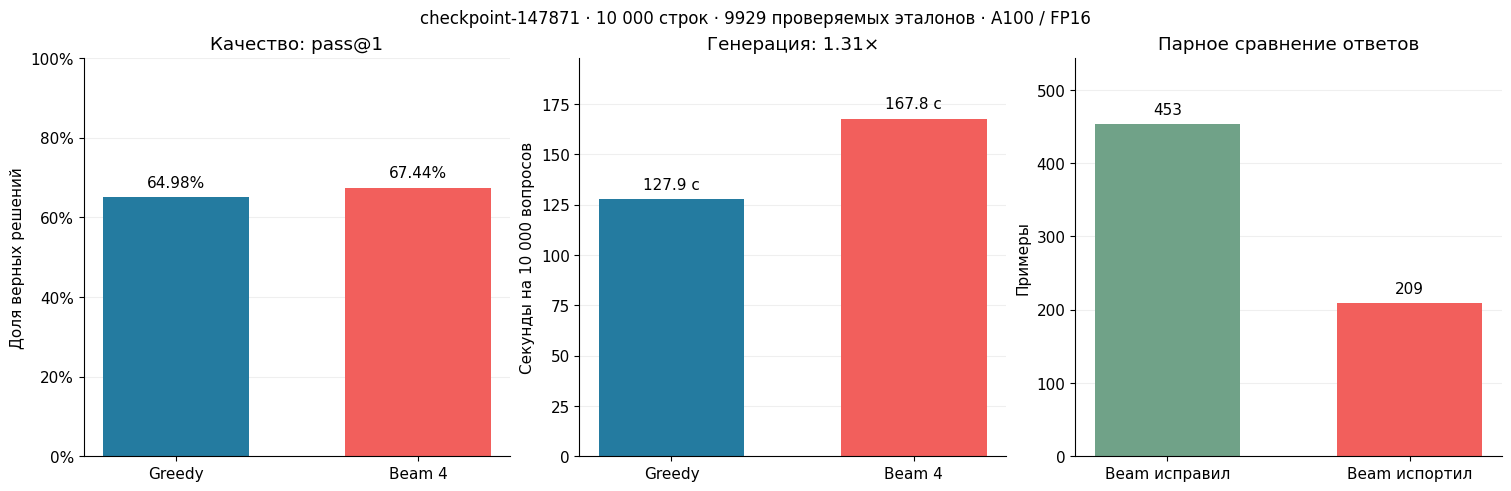

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), constrained_layout=True)
colors = ["#247BA0", "#F25F5C"]
labels = ["Greedy", "Beam 4"]
ax = axes[0]
bars = ax.bar(labels, [greedy['pass@1'], beam['pass@1']], color=colors, width=0.6)
ax.bar_label(bars, labels=[f"{greedy['pass@1']:.2%}", f"{beam['pass@1']:.2%}"], padding=5)
ax.set(title="Качество: pass@1", ylabel="Доля верных решений", ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax = axes[1]
bars = ax.bar(labels, [greedy['total_seconds'], beam['total_seconds']], color=colors, width=0.6)
ax.bar_label(bars, labels=[f"{greedy['total_seconds']:.1f} с", f"{beam['total_seconds']:.1f} с"], padding=5)
ax.set(title=f"Генерация: {comparison['inference_time_ratio']:.2f}×", ylabel="Секунды на 10 000 вопросов")
ax.set_ylim(0, max(greedy['total_seconds'], beam['total_seconds']) * 1.18)
ax = axes[2]
counts = comparison['paired_counts']
bars = ax.bar(["Beam исправил", "Beam испортил"], [counts['beam_only_correct'], counts['greedy_only_correct']], color=["#70A288", "#F25F5C"], width=0.6)
ax.bar_label(bars, padding=5)
ax.set(title="Парное сравнение ответов", ylabel="Примеры")
ax.set_ylim(0, max(counts['beam_only_correct'], counts['greedy_only_correct'], 1) * 1.2)
for ax in axes:
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
fig.suptitle(f"checkpoint-147871 · 10 000 строк · {beam['num_evaluated']} проверяемых эталонов · A100 / FP16", fontsize=12)
fig.savefig(PLOT_DIR / "beam4_comparison.png", dpi=160)
fig.savefig(PLOT_DIR / "beam4_comparison.pdf")
plt.show()

## Какие ответы изменились

Проверены идентичность вопросов, эталонного кода, индексов строк и результатов выполнения эталонов. Ниже примеры, где beam исправил ошибку greedy, и обратные случаи. Показываются первые три примера каждого типа; полные предсказания сохранены в JSONL.

In [4]:
counts = comparison['paired_counts']
display(Markdown(
    f"Правильны оба: **{counts['both_correct']}**; "
    f"правилен только beam: **{counts['beam_only_correct']}**; "
    f"правилен только greedy: **{counts['greedy_only_correct']}**; "
    f"ошиблись оба: **{counts['neither_correct']}**."
))
examples = json.loads((BEAM_DIR / 'changed_examples.json').read_text())
for key, title in [('beam_improved', 'Beam исправил'), ('beam_regressed', 'Beam испортил')]:
    display(Markdown(f"### {title}"))
    if not examples[key]:
        display(Markdown("Таких примеров нет."))
    for item in examples[key][:3]:
        display(Markdown(f"**Строка {item['source_row_index']}** · {item['question']}\n\nЭталонный ответ: `{item['reference_result']}`"))
        for mode in ('greedy', 'beam'):
            display(Markdown(f"**{mode}:** {item[mode + '_status']} · ответ `{item[mode + '_result']}`"))
            display(Code(item[mode + '_code'][:3000], language='python'))

Правильны оба: **6243**; правилен только beam: **453**; правилен только greedy: **209**; ошиблись оба: **3024**.

### Beam исправил

**Строка 3999824** · Sarah's bike weighs 25 kilograms. It gains 20% more weight after she installs some accessories. If the bike is valued at $200 per kilogram, how much is it worth after gaining the weight?

Эталонный ответ: `6000.0`

**greedy:** wrong_answer · ответ `30.0`

def solve() -> int:
    bike_weight = 25
    weight_gain = bike_weight * 0.2
    bike_worth = bike_weight + weight_gain
    result = bike_worth
    return result

...

**Строка 7791629** · A pizza has a diameter of 16 inches. What is the circumference of the pizza?

Эталонный ответ: `50.24`

**greedy:** passed · ответ `50.24`

def solve() -> int:
    diameter = 16
    radius = diameter / 2
    pi = 3.14
    circumference = 2 * pi * radius
    result = circumference
    return result

**beam:** wrong_answer · ответ `50.26548245743669`

def solve() -> int:
    import math
    diameter = 16
    radius = diameter / 2
    circumference = 2 * math.pi * radius
    result = circumference
    return result

## Что учитывать при выводах

- Это локальное сравнение результатов `solve()`, официальный test и скрытый checker здесь не используются.
- Beam search оценивает один выбранный код, а не успех любого из четырёх кандидатов.
- Разбиение сделано по строкам; повторяющиеся вопросы могут встречаться между частями. Bootstrap-интервал приближённый, зависимости повторов он не учитывает.
- Замеры A100 не подтверждают скорость beam search на T4. Время зависит от длины генерации и числа beams.
- У beam сохраняются настройки checkpoint для `length_penalty` и `early_stopping`; кроме `num_beams` режим генерации не менялся.

In [5]:
print("length_penalty:", beam['generation_length_penalty'])
print("early_stopping:", beam['generation_early_stopping'])
print("Результаты beam:", BEAM_DIR)
print("Графики:", PLOT_DIR)
print("Количество неисполнимых эталонов:", beam['num_examples'] - beam['num_evaluated'])

length_penalty: 1.0
early_stopping: False
Результаты beam: /Users/artyom-step/nlp-hw2/artifacts/beam_search_20261013/beam4
Графики: /Users/artyom-step/nlp-hw2/artifacts/beam_search_20261013/plots
Количество неисполнимых эталонов: 71
